# PRML Project - Human Activity Recognition (HAR)

**Dataset:** UCI HAR Dataset (Kaggle version)
**Samples:** 10,299 rows
**Features:** 561 features + 1 target (6 classes)
**Task:** Multiclass Classification (6 activities)

## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load data
train_path = '../data/train.csv'
test_path = '../data/test.csv'

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print(f'Train shape: {train_df.shape}')
print(f'Test shape: {test_df.shape}')
print(f'Train columns: {train_df.columns.tolist()[:5]}...')
print(f'Target column: {train_df.columns[-1]}')

Train shape: (7352, 563)
Test shape: (2947, 563)
Train columns: ['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y']...
Target column: Activity


## 2. Basic Info & Missing Values

In [2]:
print('=== Train Info ===')
print(train_df.info())

print('\n=== Missing Values ===')
print(f'Train missing: {train_df.isnull().sum().sum()}')
print(f'Test missing: {test_df.isnull().sum().sum()}')

print('\n=== Target Distribution ===')
print(train_df.iloc[:, -1].value_counts().sort_index())

=== Train Info ===
<class 'pandas.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 563 entries, tBodyAcc-mean()-X to Activity
dtypes: float64(561), int64(1), str(1)
memory usage: 31.6 MB
None

=== Missing Values ===
Train missing: 0
Test missing: 0

=== Target Distribution ===
Activity
LAYING                1407
SITTING               1286
STANDING              1374
WALKING               1226
WALKING_DOWNSTAIRS     986
WALKING_UPSTAIRS      1073
Name: count, dtype: int64


## 3. Class Distribution Visualization

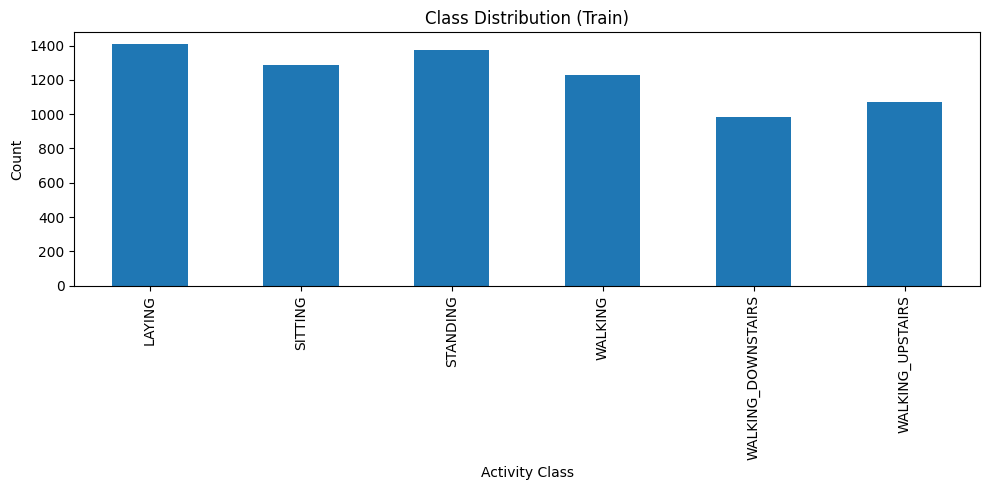

In [3]:
plt.figure(figsize=(10, 5))
train_df.iloc[:, -1].value_counts().sort_index().plot(kind='bar')
plt.title('Class Distribution (Train)')
plt.xlabel('Activity Class')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('../presentation/class_distribution.png', dpi=150)
plt.show()

## 4. Feature Statistics

In [4]:
X_train = train_df.iloc[:, :-1]
y_train = train_df.iloc[:, -1]
X_test = test_df.iloc[:, :-1]
y_test = test_df.iloc[:, -1]

print('Feature stats:')
print(X_train.describe().T[['mean', 'std', 'min', 'max']].head(10))

Feature stats:
                       mean       std       min       max
tBodyAcc-mean()-X  0.274488  0.070261 -1.000000  1.000000
tBodyAcc-mean()-Y -0.017695  0.040811 -1.000000  1.000000
tBodyAcc-mean()-Z -0.109141  0.056635 -1.000000  1.000000
tBodyAcc-std()-X  -0.605438  0.448734 -1.000000  1.000000
tBodyAcc-std()-Y  -0.510938  0.502645 -0.999873  0.916238
tBodyAcc-std()-Z  -0.604754  0.418687 -1.000000  1.000000
tBodyAcc-mad()-X  -0.630512  0.424073 -1.000000  1.000000
tBodyAcc-mad()-Y  -0.526907  0.485942 -1.000000  0.967664
tBodyAcc-mad()-Z  -0.606150  0.414122 -1.000000  1.000000
tBodyAcc-max()-X  -0.468604  0.544547 -1.000000  1.000000


## 5. Correlation Heatmap (Sample of Features)

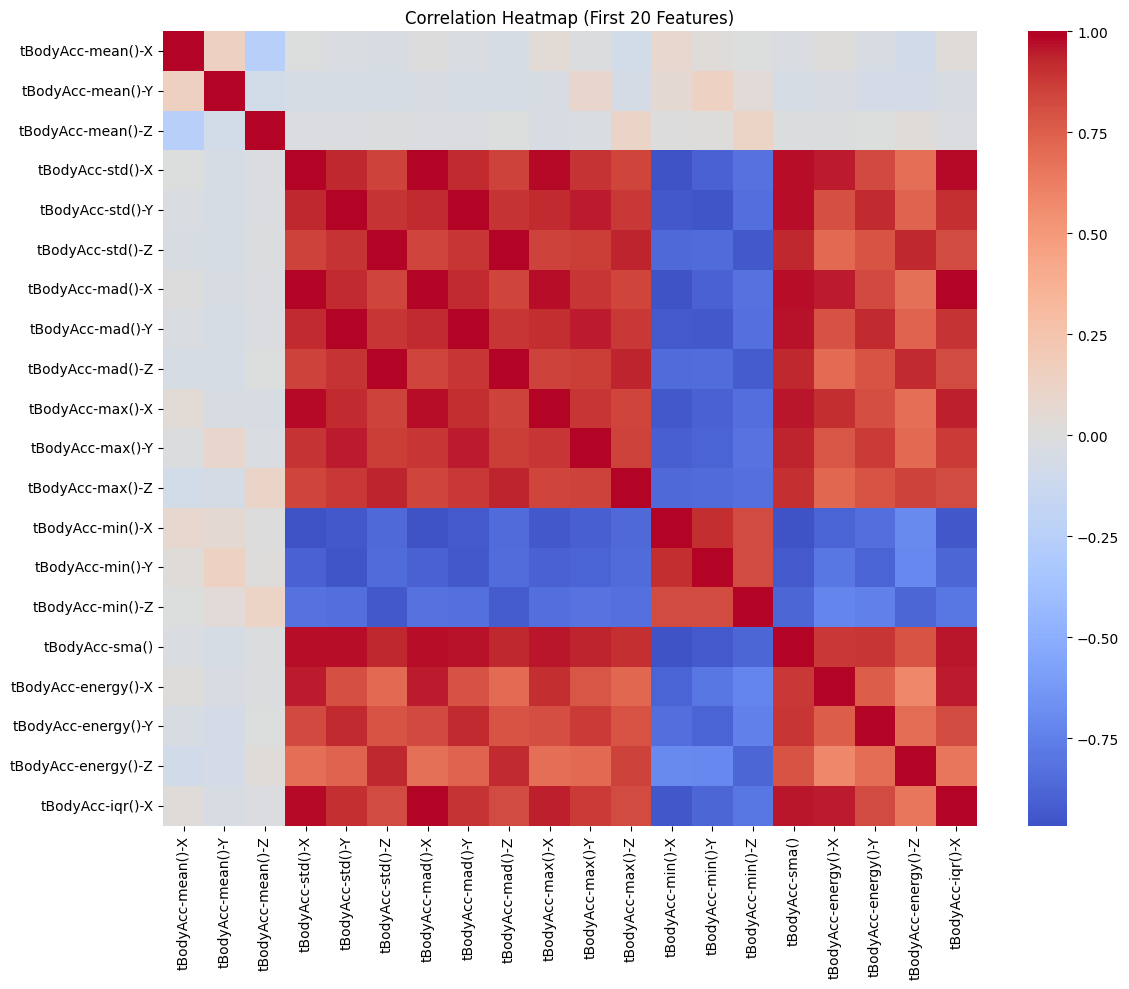

In [5]:
# Sample first 20 features for correlation
corr_sample = X_train.iloc[:, :20].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_sample, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap (First 20 Features)')
plt.tight_layout()
plt.savefig('../presentation/correlation_heatmap.png', dpi=150)
plt.show()

## 6. Save Processed Data

In [6]:
# Save for later use
import joblib
joblib.dump((X_train, y_train, X_test, y_test), '../data/processed_data.pkl')
print('Data saved to processed_data.pkl')

Data saved to processed_data.pkl
